# Portfolio Risk Analysis: Volatility, Value at Risk and Drawdown
**Author:** Victor Chigbu

**Question:** How risky is a stock portfolio, how much could it lose in a bad month, and how much capital should be set aside to absorb that loss?

**Approach:** Using monthly prices for four large US stocks (2000 to 2010), I measure risk several ways: volatility, Value at Risk (VaR), Expected Shortfall, drawdown and a Monte Carlo simulation. I then test whether VaR holds up in a backtest and whether re-weighting the portfolio can reduce risk.

**Why this period?** It contains two major crashes (the dot-com bust and the 2008 financial crisis), which makes it a good stress test.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize

pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")

## 2. Load the data
Monthly closing prices from the `vega-datasets` collection. I use AAPL, AMZN, IBM and MSFT. GOOG is excluded because it only starts in 2004, and a shorter history would drop the dot-com crash from the analysis.

In [2]:
url = "https://raw.githubusercontent.com/vega/vega-datasets/main/data/stocks.csv"
raw = pd.read_csv(url)
raw["date"] = pd.to_datetime(raw["date"], format="%b %d %Y")
prices = raw.pivot(index="date", columns="symbol", values="price").sort_index()

print("Missing values before filtering:")
print(prices.isna().sum())

prices = prices[["AAPL", "AMZN", "IBM", "MSFT"]].dropna()
print(f"\n{prices.shape[0]} months, {prices.index.min():%b %Y} to {prices.index.max():%b %Y}")
prices.head()

Missing values before filtering:
symbol
AAPL     0
AMZN     0
GOOG    55
IBM      0
MSFT     0
dtype: int64

123 months, Jan 2000 to Mar 2010


symbol,AAPL,AMZN,IBM,MSFT
date,,,,
2000-01-01,25.940,64.560,100.520,39.810
2000-02-01,28.660,68.870,92.110,36.350
2000-03-01,33.950,67.000,106.110,43.220
2000-04-01,31.010,55.190,99.950,28.370
2000-05-01,21.000,48.310,96.310,25.450


**Observation:** The data is monthly, so I have about 120 return observations per stock. That is enough to see broad patterns, but not enough to estimate extreme (99%) losses reliably. I come back to this limitation later.

## 3. Prices and returns
Risk is measured on **returns** (percentage change), not prices. I rebase each stock to 100 so they can be compared on one chart.

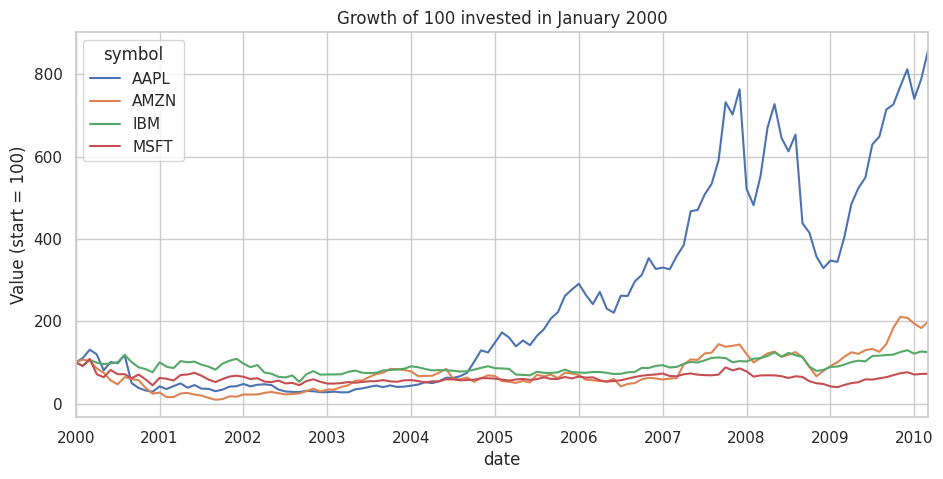

In [3]:
returns = prices.pct_change().dropna()

(prices / prices.iloc[0] * 100).plot(figsize=(11, 5), title="Growth of 100 invested in January 2000")
plt.ylabel("Value (start = 100)")
plt.show()

## 4. Risk and return of each stock
**Volatility** is the standard deviation of returns, which measures how widely returns swing. Annual figures are approximated: return x 12, volatility x square root of 12. I assume a risk-free rate of 0 to keep the focus on risk.

In [4]:
summary = pd.DataFrame({
    "Annual return": returns.mean() * 12,
    "Annual volatility": returns.std() * np.sqrt(12),
    "Return per unit of risk": (returns.mean() * 12) / (returns.std() * np.sqrt(12)),
    "Worst month": returns.min(),
    "Best month": returns.max(),
})
summary

,Annual return,Annual volatility,Return per unit of risk,Worst month,Best month
symbol,,,,,
AAPL,0.353,0.506,0.698,-0.577,0.453
AMZN,0.241,0.595,0.405,-0.411,0.622
IBM,0.064,0.295,0.217,-0.226,0.354
MSFT,0.026,0.344,0.077,-0.344,0.407


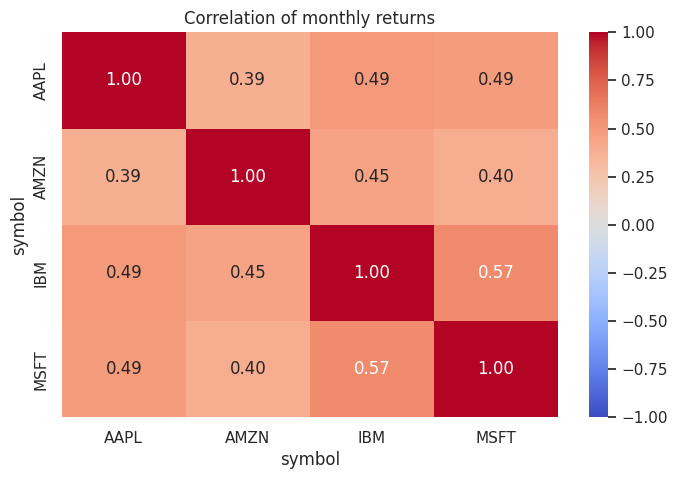

In [5]:
plt.figure(figsize=(8, 5))
sns.heatmap(returns.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation of monthly returns")
plt.show()

**Why correlation matters:** two assets that don't move together offset each other's swings, which lowers portfolio risk. This is diversification.

## 5. An equal-weight portfolio
I put 25% in each stock (rebalanced monthly) and compare its volatility with the average volatility of its parts.

In [6]:
n = returns.shape[1]
w_eq = np.repeat(1 / n, n)
port = returns @ w_eq

vol_stocks = returns.std() * np.sqrt(12)
vol_avg = (w_eq * vol_stocks).sum()
vol_port = port.std() * np.sqrt(12)

print(f"Weighted average of individual volatilities: {vol_avg:.1%}")
print(f"Actual portfolio volatility:                 {vol_port:.1%}")
print(f"Risk removed by diversification:             {vol_avg - vol_port:.1%} points")

Weighted average of individual volatilities: 43.5%
Actual portfolio volatility:                 33.5%
Risk removed by diversification:             10.0% points


## 6. Value at Risk (VaR) and Expected Shortfall
**VaR** answers: *with 95% confidence, what is the most I should expect to lose in one month?* **Expected Shortfall (ES)** answers: *when losses do exceed VaR, how bad are they on average?* A bank holds capital against losses like these, so these numbers link directly to capital requirements.

I use two methods:
- **Historical:** read the loss straight from past returns, no assumptions
- **Parametric:** assume returns are normally distributed

In [7]:
INVESTMENT = 100_000

def hist_var(r, level):   return -np.percentile(r, (1 - level) * 100)
def hist_es(r, level):
    cutoff = np.percentile(r, (1 - level) * 100)
    return -r[r <= cutoff].mean()
def param_var(r, level):  return -(r.mean() + stats.norm.ppf(1 - level) * r.std())

rows = []
for level in (0.95, 0.99):
    rows.append({
        "Confidence": f"{level:.0%}",
        "Historical VaR": hist_var(port, level),
        "Parametric VaR": param_var(port, level),
        "Expected Shortfall": hist_es(port, level),
    })
var_table = pd.DataFrame(rows).set_index("Confidence")
display(var_table.map(lambda x: f"{x:.1%}"))

print(f"\nOn a ${INVESTMENT:,} portfolio, the 95% historical monthly VaR is "
      f"${hist_var(port, .95) * INVESTMENT:,.0f}")
print(f"and the 95% Expected Shortfall is ${hist_es(port, .95) * INVESTMENT:,.0f}")

,Historical VaR,Parametric VaR,Expected Shortfall
Confidence,,,
95%,15.8%,14.5%,18.3%
99%,19.6%,21.1%,21.7%



On a $100,000 portfolio, the 95% historical monthly VaR is $15,833
and the 95% Expected Shortfall is $18,301


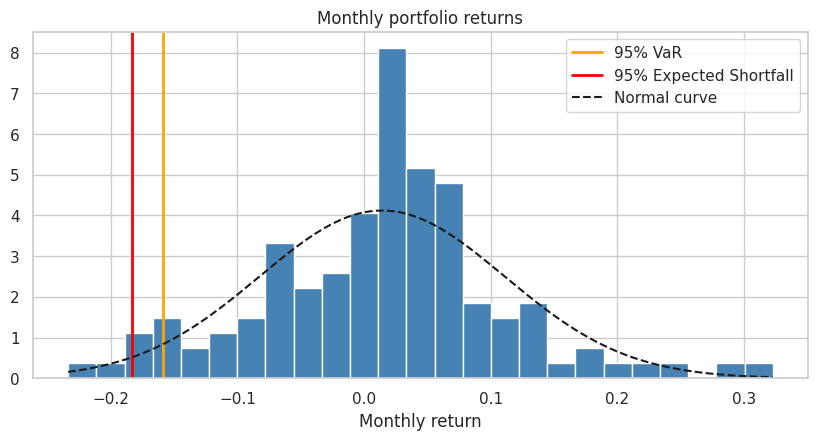

Skewness: 0.14   Excess kurtosis: 0.79


In [8]:
plt.figure(figsize=(10, 4.5))
plt.hist(port, bins=25, color="steelblue", edgecolor="white", density=True)
plt.axvline(-hist_var(port, .95), color="orange", lw=2, label="95% VaR")
plt.axvline(-hist_es(port, .95), color="red", lw=2, label="95% Expected Shortfall")
x = np.linspace(port.min(), port.max(), 200)
plt.plot(x, stats.norm.pdf(x, port.mean(), port.std()), "k--", label="Normal curve")
plt.title("Monthly portfolio returns")
plt.xlabel("Monthly return")
plt.legend()
plt.show()

print(f"Skewness: {stats.skew(port):.2f}   Excess kurtosis: {stats.kurtosis(port):.2f}")

**Interpretation note:** if the histogram has fatter tails than the dashed normal curve (positive excess kurtosis) or is skewed to the left, the normal assumption understates the real risk.

## 7. Backtest: does 95% VaR hold up?
A VaR model should be wrong about 5% of the time at the 95% level. I recompute VaR each month using only the previous 36 months, then count the months where the actual loss was bigger.

In [9]:
window = 36
breaches = []
for t in range(window, len(port)):
    var_t = hist_var(port.iloc[t - window:t], 0.95)
    if port.iloc[t] < -var_t:
        breaches.append(port.index[t])

tests = len(port) - window
print(f"Months tested: {tests}")
print(f"Breaches: {len(breaches)} ({len(breaches) / tests:.1%}; expected about 5%)")
print("Breach months:", [d.strftime('%b %Y') for d in breaches])

Months tested: 86
Breaches: 7 (8.1%; expected about 5%)
Breach months: ['Feb 2006', 'Jan 2008', 'Feb 2008', 'Jun 2008', 'Sep 2008', 'Oct 2008', 'Nov 2008']


## 8. Drawdown
**Maximum drawdown** is the largest peak-to-trough fall in portfolio value. It shows how painful the worst stretch was, which monthly VaR alone doesn't capture.

Maximum drawdown: -64.3%
Peak: Mar 2000   Trough: Sep 2001


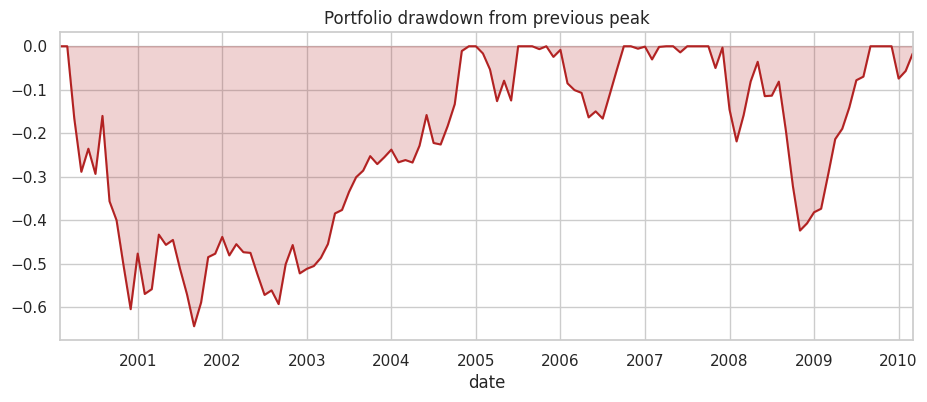

In [10]:
wealth = (1 + port).cumprod()
peak = wealth.cummax()
drawdown = wealth / peak - 1

trough = drawdown.idxmin()
peak_date = wealth.loc[:trough].idxmax()
print(f"Maximum drawdown: {drawdown.min():.1%}")
print(f"Peak: {peak_date:%b %Y}   Trough: {trough:%b %Y}")

drawdown.plot(figsize=(11, 4), color="firebrick", title="Portfolio drawdown from previous peak")
plt.fill_between(drawdown.index, drawdown, color="firebrick", alpha=0.2)
plt.show()

## 9. Stress test: the two crashes
How did the portfolio do in each crisis window?

In [11]:
windows = {
    "Dot-com bust (Jan 2000 to Sep 2002)": ("2000-01-01", "2002-09-30"),
    "Financial crisis (Sep 2008 to Feb 2009)": ("2008-09-01", "2009-02-28"),
}
rows = []
for name, (a, b) in windows.items():
    r = port.loc[a:b]
    rows.append({"Window": name, "Months": len(r),
                 "Portfolio cumulative return": (1 + r).prod() - 1,
                 "Worst month": r.min()})
pd.DataFrame(rows).set_index("Window").style.format({
    "Portfolio cumulative return": "{:.1%}", "Worst month": "{:.1%}"})

,Months,Portfolio cumulative return,Worst month
Window,,,
Dot-com bust (Jan 2000 to Sep 2002),32,-54.1%,-23.4%
Financial crisis (Sep 2008 to Feb 2009),6,-31.8%,-15.9%


## 10. Monte Carlo simulation: one-year capital at risk
I simulate 10,000 possible years of monthly returns, using each stock's historical average, volatility and correlation, and look at the bad outcomes. The 5th percentile shows what a 'bad but not worst-case' year looks like.

Median ending value:      $112,002
5th percentile value:     $64,631
1-year 95% loss (vs $100,000): $35,369
Probability of losing money after 1 year: 36.4%


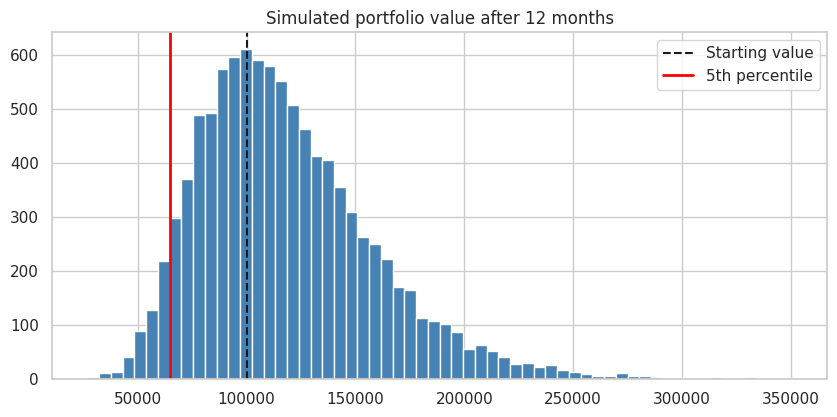

In [12]:
np.random.seed(42)
mu = returns.mean().values
cov = returns.cov().values

n_sims, months = 10_000, 12
sim = np.random.multivariate_normal(mu, cov, size=(n_sims, months))
sim_port = sim @ w_eq
end_value = INVESTMENT * np.prod(1 + sim_port, axis=1)

p5 = np.percentile(end_value, 5)
print(f"Median ending value:      ${np.median(end_value):,.0f}")
print(f"5th percentile value:     ${p5:,.0f}")
print(f"1-year 95% loss (vs ${INVESTMENT:,}): ${INVESTMENT - p5:,.0f}")
print(f"Probability of losing money after 1 year: {(end_value < INVESTMENT).mean():.1%}")

plt.figure(figsize=(10, 4.5))
plt.hist(end_value, bins=60, color="steelblue", edgecolor="white")
plt.axvline(INVESTMENT, color="k", ls="--", label="Starting value")
plt.axvline(p5, color="red", lw=2, label="5th percentile")
plt.title("Simulated portfolio value after 12 months")
plt.legend()
plt.show()

## 11. Can re-weighting reduce risk? (Minimum-variance portfolio)
Capital is limited, so a bank wants the least risk for the return it earns. I use an optimizer to find the weights (no short selling) that minimize portfolio volatility, then compare with equal weights.

In [13]:
cov_m = returns.cov().values

def vol(w):
    return np.sqrt(w @ cov_m @ w)

res = minimize(vol, w_eq, bounds=[(0, 1)] * n,
               constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
w_min = res.x

def describe(w):
    p = returns @ w
    return {"Annual return": p.mean() * 12,
            "Annual volatility": p.std() * np.sqrt(12),
            "Return per unit of risk": (p.mean() * 12) / (p.std() * np.sqrt(12)),
            "95% monthly VaR": hist_var(p, 0.95),
            "Max drawdown": ((1 + p).cumprod() / (1 + p).cumprod().cummax() - 1).min()}

compare = pd.DataFrame({"Equal weight": describe(w_eq), "Minimum variance": describe(w_min)}).T
print("Minimum-variance weights:")
print(pd.Series(w_min, index=returns.columns).map("{:.1%}".format).to_string())
compare

Minimum-variance weights:
symbol
AAPL     0.1%
AMZN     0.0%
IBM     67.2%
MSFT    32.7%


,Annual return,Annual volatility,Return per unit of risk,95% monthly VaR,Max drawdown
Equal weight,0.171,0.335,0.510,0.158,-0.643
Minimum variance,0.052,0.279,0.187,0.108,-0.507


**Caution:** these weights are optimized on past data. They describe what would have been least risky in 2000 to 2010, not what will be least risky in future. Using the same data to choose and judge the weights flatters the result (this is called in-sample bias).

## 12. Conclusions
- **Diversification helped, but not as much as it could have.** The equal-weight portfolio had 33.5% annual volatility, versus 43.5% for the weighted average of its four stocks, so combining them removed about 10 percentage points of risk. The stocks were all large technology companies with correlations between 0.39 and 0.57, so they tended to fall together. Holding assets from different sectors or classes would likely have cut risk further.
- **A bad month can be costly.** The 95% historical monthly VaR was 15.8%, or about $15,800 on a $100,000 portfolio. When losses did exceed VaR, they averaged 18.3% (Expected Shortfall). The parametric method gave a lower 95% VaR (14.5%), because real returns had fatter tails than a normal curve (excess kurtosis of 0.79). So the normal assumption understated risk.
- **VaR failed when it mattered most.** In the backtest, VaR was breached in 7 of 86 months (8.1%) against the 5% expected. Six of the seven breaches were in 2008. A VaR estimated from the previous 36 calm months did not anticipate the financial crisis, which shows that VaR looks backward and needs stress testing alongside it.
- **Drawdown shows the pain VaR hides.** The maximum drawdown was -64.3%, from March 2000 to September 2001. The portfolio lost 54.1% over the 32-month dot-com bust and 31.8% in just six months of the 2008 crisis. The Monte Carlo simulation put a bad year (5th percentile) at a loss of about $35,400, and gave a 36% chance of ending a year below the starting value.
- **Lowest risk is not the same as best.** The minimum-variance portfolio (67% IBM, 33% MSFT) cut volatility to 27.9%, 95% VaR to 10.8% and maximum drawdown to -50.7%. But its annual return fell from 17.1% to 5.2%, so return per unit of risk dropped from 0.51 to 0.19. Capital held against risk is only worth it if the return justifies it, and this is the trade-off a capital allocation team has to balance.
- **What surprised me:** how much of the damage came in a handful of months, and that the model that looked most careful (VaR using recent history) was weakest during the crisis.

## 13. Limitations and next steps
- **Survivorship bias:** these four companies survived and thrived. A portfolio including failed companies would look riskier.
- **Monthly data and only about 120 observations:** 99% VaR depends on one or two data points, so it is unreliable.
- **Prices only:** no dividends, transaction costs or taxes.
- **Normal assumption** in the parametric VaR and Monte Carlo can understate crash risk.
- **Next steps:** use daily data, try a GARCH model for changing volatility, add bonds or other asset classes, and test VaR with a Kupiec backtest.